# Requêtes des services IA

ModeTrends développe 'Fashion Trend Intelligence', un système qui analyse les tendances vestimentaires sur les réseaux sociaux. 

Il aura trois fonctions : segmenter les vêtements, les classifier (nature, couleur, texture, style) et agréger les tendances

### Demande de Sophia (ModeTrends):

 Evaluer si le modèle SegFormer clothes, via l’API serverless de Hugging Face, segmente correctement les vêtements sur des images annotées, puis estimer le coût pour 500 000 images sur 30 jours.

### Ce que fait ce notebook:

Il envoie des images au modèle, décode les masques renvoyés et les affiche à côté de l’image d’origine.

### Limite:

Faute de crédits (erreur 402), l’appel est simulé en local avec le même modèle et le même format de réponse. Ces résultats ne viennent pas du service.

In [91]:
import glob
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from matplotlib.patches import Patch
from PIL import Image
from tqdm.auto import tqdm
from transformers import SegformerImageProcessor, AutoModelForSemanticSegmentation

In [92]:
#dossiers
Img = 'top_influenceurs_2024/IMG'
mask = 'top_influenceurs_2024/Mask'
sortie = 'resultats'

In [93]:
#verifier fichiers existent
if not os.path.exists(Img):
    raise FileNotFoundError(f'Le dossier {Img} n\'existe pas.')
print(f'Le dossier {Img} existe.')

if not os.path.join(sortie, 'visualisations'):
    raise FileNotFoundError(f'Le dossier {os.path.join(sortie, "visualisations")} n\'existe pas.')
print(f'Le dossier {os.path.join(sortie, "visualisations")} existe.')

Le dossier top_influenceurs_2024/IMG existe.
Le dossier resultats\visualisations existe.


In [94]:
processor = SegformerImageProcessor.from_pretrained('sayeed99/segformer_b3_clothes')
model = AutoModelForSemanticSegmentation.from_pretrained('sayeed99/segformer_b3_clothes')

Loading weights: 100%|██████████| 644/644 [00:00<00:00, 4514.04it/s]


In [95]:
categories_dict = model.config.id2label
id2label = categories_dict

def segmenter(img):
    #code Hugging Face
    inputs = processor(images=img, return_tensors='pt')

    outputs = model(**inputs)
    logits = outputs.logits.cpu()

    upsampled_logits = nn.functional.interpolate(
        logits,
        size=img.size[::-1],
        mode='bilinear',
        align_corners=False,
    )

    pred_seg = upsampled_logits.argmax(dim=1)[0]
    return pred_seg.numpy()

### Simulation API:

Faute de crédits Hugging Face (erreur 402), l'appel à l'API est simulé : le modèle tourne en local et sa sortie est mise au même format que la réponse du service. 

Pour utiliser le vrai service, passer `utiliser_api_reelle` à `True`. 

In [96]:
import base64
import io
import requests

In [97]:
utiliser_api_reelle = False
API_URL = 'https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes'
CLASS_MAPPING = {nom: i for i, nom in categories_dict.items()}
CLASS_MAPPING

{'Background': 0,
 'Hat': 1,
 'Right-shoe': 10,
 'Face': 11,
 'Left-leg': 12,
 'Right-leg': 13,
 'Left-arm': 14,
 'Right-arm': 15,
 'Bag': 16,
 'Scarf': 17,
 'Hair': 2,
 'Sunglasses': 3,
 'Upper-clothes': 4,
 'Skirt': 5,
 'Pants': 6,
 'Dress': 7,
 'Belt': 8,
 'Left-shoe': 9}

Ces fonctions décodent les masques renvoyés par l'API et les assemblent en une carte de classes. `simuler_api` imite la réponse du service avec le modèle local, et `appeler_api` choisit entre la simulation et le vrai service.

In [98]:
def decode_base64_mask(base64_string, width, height):
    mask_data = base64.b64decode(base64_string)
    mask_image = Image.open(io.BytesIO(mask_data))
    mask_array = np.array(mask_image)
    if len(mask_array.shape) == 3:
        mask_array = mask_array[:, :, 0]
    mask_image = Image.fromarray(mask_array).resize((width, height), Image.NEAREST)
    return np.array(mask_image)


def create_masks(results, width, height):
    combined_mask = np.zeros((height, width), dtype=np.uint8)

    for result in results:
        class_id = CLASS_MAPPING.get(result['label'], 0)
        if class_id == 0:
            continue
        mask_array = decode_base64_mask(result['mask'], width, height)
        combined_mask[mask_array > 0] = class_id

    for result in results:
        if result['label'] == 'Background':
            mask_array = decode_base64_mask(result['mask'], width, height)
            combined_mask[mask_array > 0] = 0

    return combined_mask


def simuler_api(img):
    pred = segmenter(img)
    resultats = []
    for c in np.unique(pred):
        buffer = io.BytesIO()
        Image.fromarray(((pred == c) * 255).astype(np.uint8)).save(buffer, format='PNG')
        resultats.append({'label': categories_dict[int(c)], 'mask': base64.b64encode(buffer.getvalue()).decode()})
    return resultats


def appeler_api(img):
    if utiliser_api_reelle:
        buffer = io.BytesIO()
        img.save(buffer, format='JPEG', quality=90)
        response = requests.post(
            API_URL,
            headers={'Authorization': f'Bearer {os.environ['token_API']}', 'Content-Type': 'image/jpeg'},
            data=buffer.getvalue(),
            timeout=60,
        )
        response.raise_for_status()
        return response.json()
    return simuler_api(img)


In [99]:
if not utiliser_api_reelle:
    print('Mode simulation : l\'API Hugging Face n\'est pas appelée.')

Mode simulation : l'API Hugging Face n'est pas appelée.


In [100]:
categories = 18
seed = 42
prop = (0.6, 0.2, 0.2)

In [101]:
#vérifié l’intégrité des fichiers images
fichiers = sorted(glob.glob(os.path.join(Img, '*.*')) + glob.glob(os.path.join(mask, '*.*')))
corrompus = []
for chemin in fichiers:
    try:
        with Image.open(chemin) as f:
            f.verify()
    except Exception as e:
        corrompus.append((chemin, e))

print(len(fichiers), 'fichiers vérifiés,', len(corrompus), 'corrompu(s)')
for chemin, e in corrompus:
    print(chemin, e)

100 fichiers vérifiés, 0 corrompu(s)


Chargement des 50 photos et de leurs masques de référence, avec vérification du format des masques.

In [102]:
def numero(chemin):
    nombres = re.findall(r'\d+', os.path.basename(chemin))
    return int(nombres[-1]) if nombres else -1


fichiers_images = []
for extension in ('*.png', '*.jpg', '*.jpeg'):
    fichiers_images += glob.glob(os.path.join(Img, extension))
fichiers_images = sorted(fichiers_images, key=numero)

donnees = []
for chemin_img in fichiers_images:
    nom = os.path.splitext(os.path.basename(chemin_img))[0]
    chemin_masque = os.path.join(mask, nom.replace('image', 'mask') + '.png')
    if not os.path.exists(chemin_masque):
        print('Pas de masque pour', nom)
        continue

    img = Image.open(chemin_img).convert('RGB')
    gt = np.array(Image.open(chemin_masque))

    if gt.ndim != 2 or gt.max() >= categories or gt.shape != (img.height, img.width):
        raise ValueError(f'Masque inattendu pour {nom} : forme {gt.shape}, valeurs {np.unique(gt)[:10]}')

    donnees.append({'nom': nom, 'img': img, 'gt': gt})

print(len(donnees), 'paires chargées')

50 paires chargées


Utiliser que si `utiliser_api_reelle` est True: 

In [103]:
#appeler_api(img)

In [104]:
for d in tqdm(donnees):
    with torch.no_grad():
        d['pred'] = segmenter(d['img'])

100%|██████████| 50/50 [00:45<00:00,  1.11it/s]


In [105]:
#codes couleurs
norm = plt.Normalize(0, 17)
cmap = plt.cm.tab20

In [106]:
def comparer(d, titre_sup='', montrer=True, sauver=None):
    img, gt, pred = d['img'], d['gt'], d['pred']
    presentes = sorted(set(np.unique(gt).tolist()) | set(np.unique(pred).tolist()))
    legende = [Patch(facecolor=cmap(norm(c)), label=id2label[c]) for c in presentes]

    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    axes[0].imshow(img)
    axes[0].set_title(f'Image originale ({d['nom']}) {titre_sup}')
    axes[1].imshow(gt, cmap=cmap, norm=norm, interpolation='nearest')
    axes[1].set_title('Vérité terrain')
    axes[2].imshow(pred, cmap=cmap, norm=norm, interpolation='nearest')
    axes[2].set_title('Prédiction du modèle')
    for ax in axes:
        ax.axis('off')
    fig.legend(handles=legende, loc='lower center', ncol=min(len(legende), 9), frameon=False)
    plt.tight_layout(rect=[0, 0.07, 1, 1])

    if sauver:
        fig.savefig(sauver, dpi=110, bbox_inches='tight')
    if montrer:
        plt.show()
    else:
        plt.close(fig)

Affichage un certains nombre d'images :

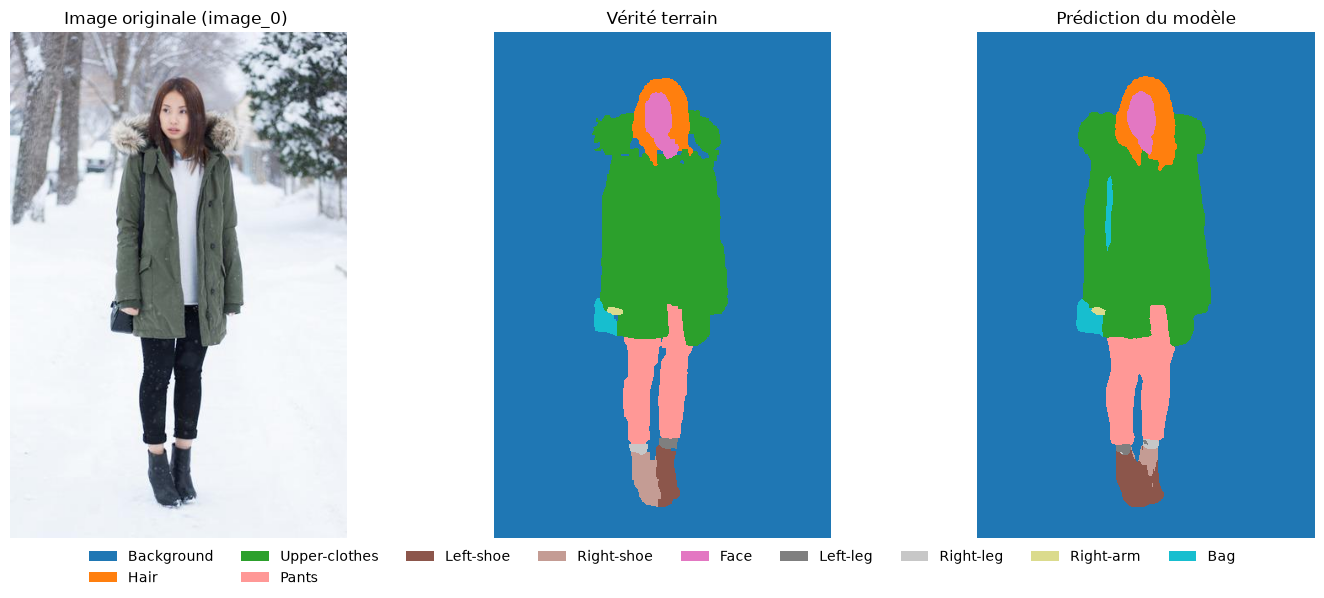

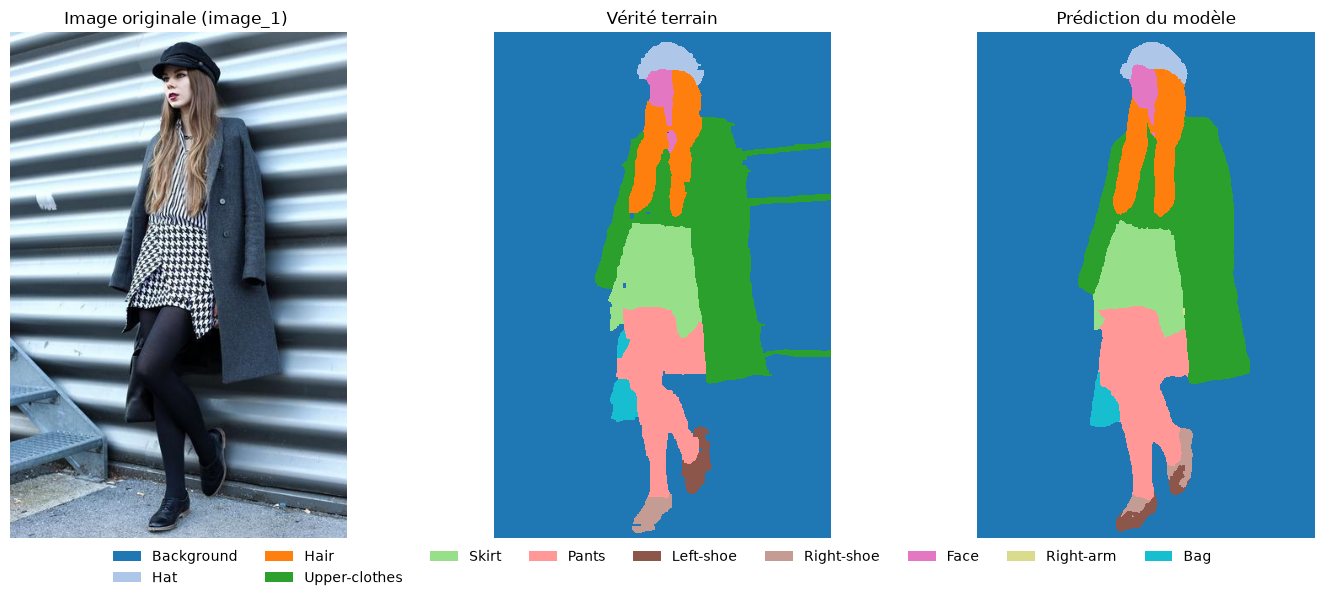

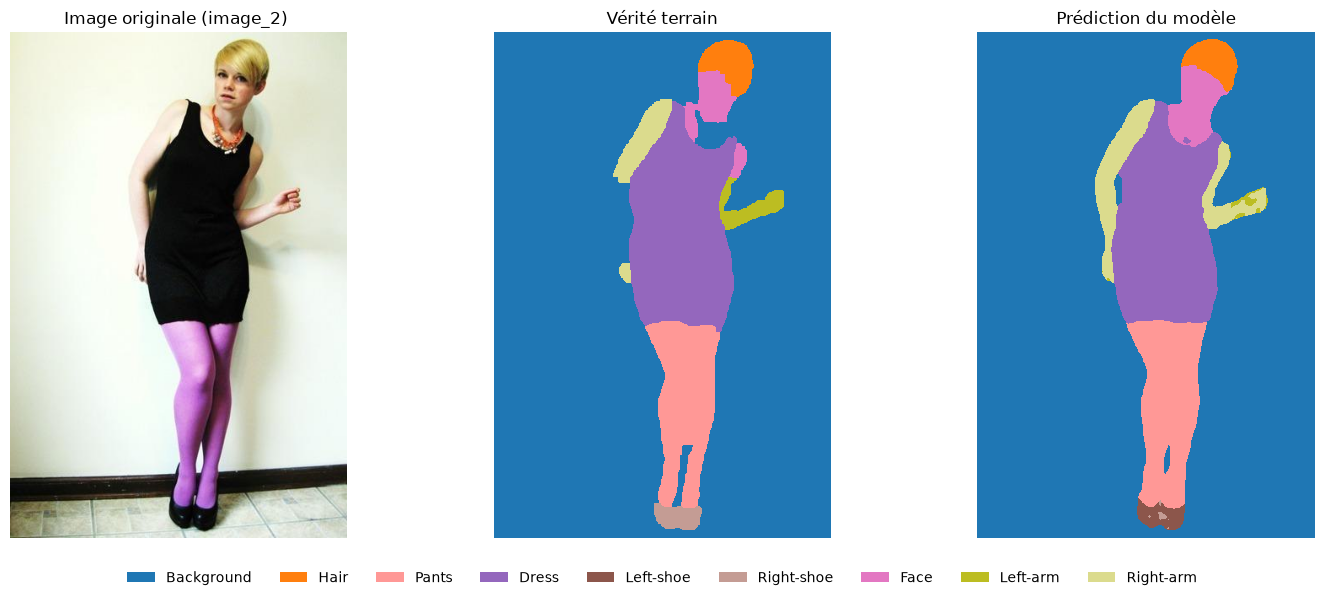

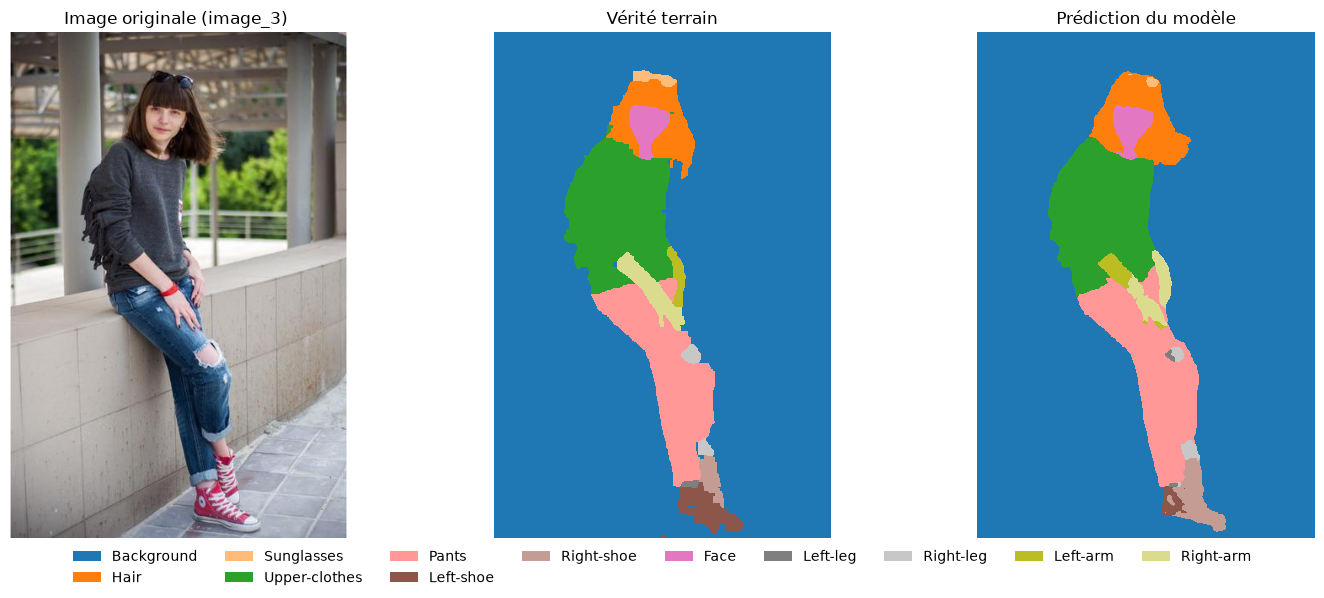

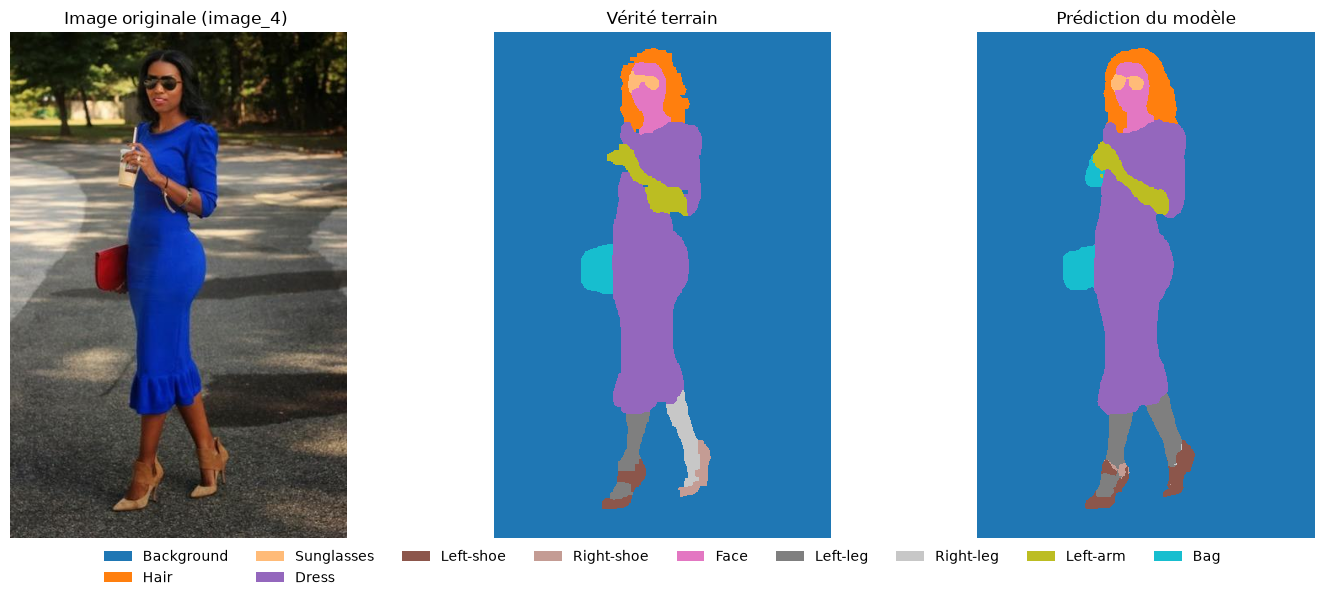

In [107]:
nb_afficher = 5
for i, d in enumerate(donnees):
    comparer(d, montrer=(i < nb_afficher),
             sauver=os.path.join(sortie, 'visualisations', f'{d['nom']}.png'))

### Calcul de métriques:

pour chaque classe, on compte les pixels bien classés, prédits et réels, puis on en déduit l'IoU et le Dice. `evaluer` regroupe ces comptes sur un ensemble d'images

`compter`-> Pour une image et chaque classe c (catégories de 0-17) on calcule:
+ les pixels que le modèle + la vérité terrain attribuent à c
+ les pixels que le modèle attribue à c
+ les pixels qui sont vraiment c d’après la vérité terrain

In [108]:
def compter(pred, gt):
    inter = np.zeros(categories, dtype=np.int64)
    aire_pred = np.zeros(categories, dtype=np.int64)
    aire_gt = np.zeros(categories, dtype=np.int64)
    for c in range(categories):
        p = pred == c
        g = gt == c
        inter[c] = np.logical_and(p, g).sum()
        aire_pred[c] = p.sum()
        aire_gt[c] = g.sum()
    return inter, aire_pred, aire_gt

`iou_dice`-> À partir de ces trois nombres:

IoU  = inter / (aire_pred + aire_gt - inter) <br>
Dice = 2 x inter / (aire_pred + aire_gt)

In [109]:
def iou_dice(inter, aire_pred, aire_gt):
    union = aire_pred + aire_gt - inter
    total = aire_pred + aire_gt
    iou = np.where(union > 0, inter / np.maximum(union, 1), np.nan)
    dice = np.where(total > 0, 2 * inter / np.maximum(total, 1), np.nan)
    return iou, dice

In [110]:
def evaluer(idx, fusion=None):
    comptes = []
    for i in idx:
        d = donnees[i]
        if fusion is None:
            comptes.append(d['compte'])
        else:
            comptes.append(compter(fusion[d['pred']], fusion[d['gt']]))
    inter = sum(c[0] for c in comptes)
    aire_pred = sum(c[1] for c in comptes)
    aire_gt = sum(c[2] for c in comptes)
    return iou_dice(inter, aire_pred, aire_gt)

#calcule une fois les compteurs de chaque image et les range
for d in donnees:
    d['compte'] = compter(d['pred'], d['gt'])

### Evaluations métriques:

Découpage:

In [111]:
rng = np.random.default_rng(seed)
ordre = rng.permutation(len(donnees))

n_train = int(prop[0] * len(donnees)) #0,6 x 50 = 30
n_val = int(prop[1] * len(donnees)) #0,2 x 50 = 10

In [112]:
#tableau des indices pour chaque jeu de données
indices = {
    'train': ordre[:n_train],
    'validation': ordre[n_train:n_train + n_val],
    'test': ordre[n_train + n_val:],
}

print(f'{'jeu':12s} {'images':>7s} {'mean IoU':>9s} {'mean Dice':>10s}')

for nom_jeu, idx in {**indices, 'tout': range(len(donnees))}.items():
    iou, dice = evaluer(idx)
    print(f'{nom_jeu:12s} {len(idx):7d} {np.nanmean(iou):9.3f} {np.nanmean(dice):10.3f}')

jeu           images  mean IoU  mean Dice
train             30     0.659      0.761
validation        10     0.613      0.708
test              10     0.651      0.758
tout              50     0.652      0.756


In [113]:
#garde les scores des 50 images dans deux variables réutilisables
iou_tout, dice_tout = evaluer(range(len(donnees)))

In [114]:
#IoU publiés par l'auteur
IOU_PUBLIE = [0.99, 0.68, 0.82, 0.63, 0.78, 0.65, 0.84, 0.55, 0.30,
              0.58, 0.60, 0.85, 0.82, 0.81, 0.74, 0.73, 0.84, 0.29]

#tabl comparatif des scores par classe
print(f'{'classe':15s} {'IoU':>6s} {'Dice':>6s} {'IoU publié':>11s}')
for c in range(categories):
    iou_txt = '-' if np.isnan(iou_tout[c]) else f'{iou_tout[c]:.2f}'
    dice_txt = '-' if np.isnan(dice_tout[c]) else f'{dice_tout[c]:.2f}'
    print(f'{id2label[c]:15s} {iou_txt:>6s} {dice_txt:>6s} {IOU_PUBLIE[c]:>11.2f}')

classe             IoU   Dice  IoU publié
Background        0.99   0.99        0.99
Hat               0.86   0.92        0.68
Hair              0.81   0.89        0.82
Sunglasses        0.70   0.83        0.63
Upper-clothes     0.89   0.94        0.78
Skirt             0.94   0.97        0.65
Pants             0.91   0.95        0.84
Dress             0.80   0.89        0.55
Belt              0.56   0.72        0.30
Left-shoe         0.31   0.48        0.58
Right-shoe        0.20   0.34        0.60
Face              0.84   0.91        0.85
Left-leg          0.43   0.60        0.82
Right-leg         0.24   0.39        0.81
Left-arm          0.35   0.52        0.74
Right-arm         0.34   0.51        0.73
Bag               0.74   0.85        0.84
Scarf             0.82   0.90        0.29


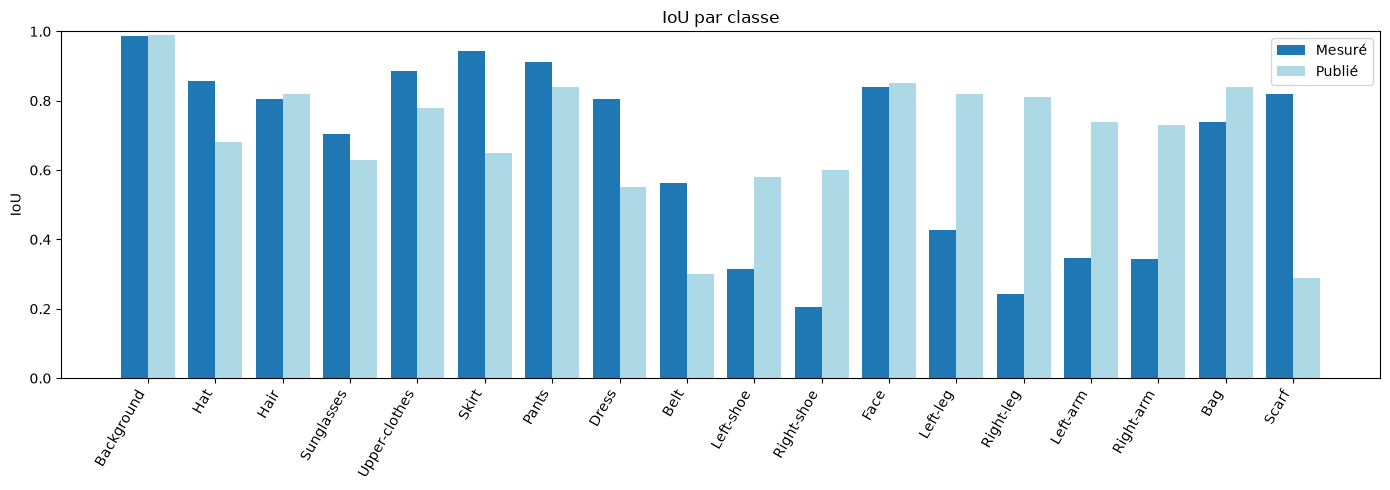

In [115]:
x = np.arange(categories)
plt.figure(figsize=(14, 5))
plt.bar(x - 0.2, np.nan_to_num(iou_tout), 0.4, label='Mesuré')
plt.bar(x + 0.2, IOU_PUBLIE, 0.4, label='Publié', color='lightblue')
plt.xticks(x, [id2label[c] for c in range(categories)], rotation=60, ha='right')
plt.ylim(0, 1)
plt.ylabel('IoU')
plt.title('IoU par classe')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(sortie, 'iou_par_classe.png'), dpi=110, bbox_inches='tight')
plt.show()

Sur les classes principales, nos résultats sont cohérents avec ceux annoncés par l’auteur du modèle. <br>
Le modèle distingue mal la gauche de la droite (chaussures, jambes, bras), ce qui n’a pas d’impact pour identifier les vêtements portés. 

Ces scores sont indicatifs: ils reposent sur 50 images, probablement déjà vues par le modèle à l’entraînement.

Pour chaque groupe, on regarde si le modèle a trouvé une chaussure (ou jambe, ou bras) au bon endroit, sans se préoccuper de savoir si c’est la gauche ou la droite.

In [116]:
groupes = {"chaussures": [9, 10], "jambes": [12, 13], "bras": [14, 15]}

for nom, ids in groupes.items():
    inter = union = 0
    for d in donnees:
        p = np.isin(d["pred"], ids)
        g = np.isin(d["gt"], ids)
        inter += np.logical_and(p, g).sum()
        union += np.logical_or(p, g).sum()
    print(f"{nom:11s} {iou_tout[ids[0]]:.2f} / {iou_tout[ids[1]]:.2f} -> {inter / union:.2f}")

chaussures  0.31 / 0.20 -> 0.76
jambes      0.43 / 0.24 -> 0.90
bras        0.35 / 0.34 -> 0.81


classe les 50 images de la moins bien segmentée à la mieux segmentée

image_26 : IoU moyen 0.41
image_28 : IoU moyen 0.43
image_34 : IoU moyen 0.44
image_39 : IoU moyen 0.45
image_46 : IoU moyen 0.45


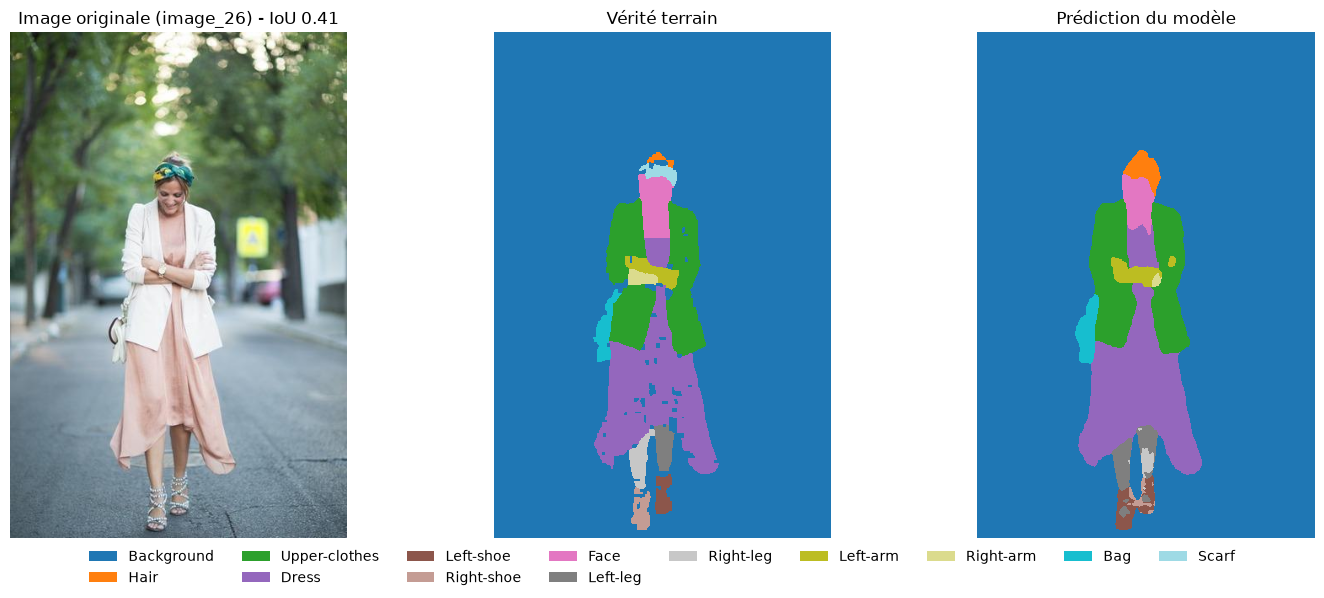

In [117]:
iou_par_image = sorted((np.nanmean(iou_dice(*d['compte'])[0]), i) for i, d in enumerate(donnees))

for score, i in iou_par_image[:5]:
    print(f'{donnees[i]['nom']} : IoU moyen {score:.2f}')

score, i = iou_par_image[0]
comparer(donnees[i], titre_sup=f'- IoU {score:.2f}')

In [118]:
vetements = [1, 3, 4, 5, 6, 7, 8, 9, 10, 16, 17]
seuil_presence = 0.002

In [119]:
def present(masque, c):
    return (masque == c).mean() >= seuil_presence

pct_modele = [100 * np.mean([present(d['pred'], c) for d in donnees]) for c in vetements]
pct_verite = [100 * np.mean([present(d['gt'], c) for d in donnees]) for c in vetements]

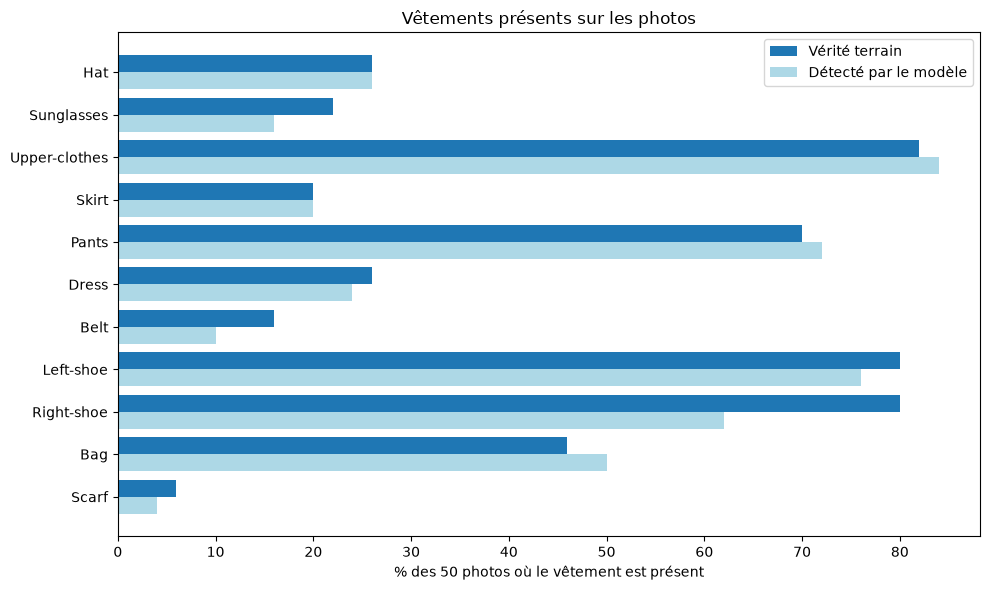

In [120]:
y = np.arange(len(vetements))
plt.figure(figsize=(10, 6))
plt.barh(y - 0.2, pct_verite, 0.4, label='Vérité terrain')
plt.barh(y + 0.2, pct_modele, 0.4, label='Détecté par le modèle', color='lightblue')
plt.yticks(y, [id2label[c] for c in vetements])
plt.gca().invert_yaxis()
plt.xlabel(f'% des {len(donnees)} photos où le vêtement est présent')
plt.title('Vêtements présents sur les photos')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(sortie, 'vetements_presents.png'), dpi=110, bbox_inches='tight')
plt.show()

Part des 50 photos où chaque vêtement est présent, selon la vérité terrain et selon le modèle. <br>
Les pièces principales (haut, pantalon, robe, jupe, chapeau, sac) sont détectées à 0, 1 ou 2 photos près. Les petits accessoires (lunettes, ceinture) sont légèrement sous-détectés. 

L'écart sur la chaussure droite vient probablement de la confusion entre chaussure gauche et droite.

Mesure de la latence: temps moyen pour segmenter une image

In [121]:
import time

durees = []
for d in donnees[:11]:
    debut = time.perf_counter()
    with torch.no_grad():
        segmenter(d['img'])
    durees.append(time.perf_counter() - debut)
latence = np.mean(durees[1:])

Dimensionnement pour 500 000 images en 30 jours: débit à tenir, nombre d'instances nécessaires, et coût selon l'hypothèse de prix d'une instance

In [122]:
prix_heure = 0.067
nb_images, jours = 500_000, 30
debit_requis = nb_images / (jours * 86400)
instances = int(np.ceil(debit_requis * latence))

In [124]:
print(f'latence : {latence:.2f} s/image, soit {1 / latence:.2f} image/s par instance')
print(f'débit requis : {debit_requis:.3f} image/s ({debit_requis * 86400:.0f} par jour)')
print(f'capacité d\'une instance : {86400 / latence:.0f} images/jour')
print(f'instances nécessaires : {instances}')
print(f'coût par image : {latence * prix_heure / 3600:.7f} $')
print(f'coût à la consommation : {nb_images * latence * prix_heure / 3600:.2f} $')
print(f'coût en instance dédiée 24h/24 : {instances * prix_heure * jours * 24:.2f} $')

latence : 1.26 s/image, soit 0.80 image/s par instance
débit requis : 0.193 image/s (16667 par jour)
capacité d'une instance : 68718 images/jour
instances nécessaires : 1
coût par image : 0.0000234 $
coût à la consommation : 11.70 $
coût en instance dédiée 24h/24 : 48.24 $
